# Partial



In [16]:
import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

np.random.seed(12)

def deseneaza_neorientat(muchii, poz, titlu, culori=None, figsize=(7, 2.6)):
    fig, ax = plt.subplots(figsize=figsize)
    for a, b in muchii:
        ax.plot([poz[a][0], poz[b][0]], [poz[a][1], poz[b][1]], color="black", lw=2, zorder=1)
    for v, (x, y) in poz.items():
        c = (culori or {}).get(v, "#8ecae6")
        ax.scatter([x], [y], s=1800, color=c, edgecolor="black", zorder=3)
        ax.text(x, y, v, ha="center", va="center", fontsize=12, zorder=4)
    xs = [p[0] for p in poz.values()]; ys = [p[1] for p in poz.values()]
    ax.set_xlim(min(xs) - 0.7, max(xs) + 0.7)
    ax.set_ylim(min(ys) - 0.7, max(ys) + 0.7)
    ax.axis("off"); ax.set_title(titlu)
    plt.show()

## Subiectul 1:



In [17]:
culori_idx = {"red": 0, "green": 1, "blue": 2}
secventa = ["red", "green", "blue", "blue", "red"]
obs = [culori_idx[c] for c in secventa]

B = np.array([[0.7, 0.2, 0.1],
              [0.2, 0.6, 0.2],
              [0.1, 0.3, 0.6],
              [0.5, 0.2, 0.3]])
pi = np.full(4, 0.25)

def matrice_tranzitie(p_ramane):

    p_vecin = (1 - p_ramane) / 2
    A = np.zeros((4, 4))
    for i in range(4):
        A[i, i] = p_ramane
        A[i, (i + 1) % 4] = p_vecin
        A[i, (i - 1) % 4] = p_vecin
    return A

def viterbi(pi, A, B, o):
    T, N = len(o), len(pi)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    delta[0] = pi * B[:, o[0]]
    for t in range(1, T):
        cand = delta[t - 1][:, None] * A
        psi[t] = cand.argmax(axis=0)
        delta[t] = B[:, o[t]] * cand.max(axis=0)

    drum = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        drum.append(int(psi[t][drum[-1]]))
    return drum[::-1], delta[-1].max(), delta

def forward(pi, A, B, o):
    alfa = pi * B[:, o[0]]
    for t in range(1, len(o)):
        alfa = (alfa @ A) * B[:, o[t]]
    return alfa.sum()

def enumerare(pi, A, B, o, k=4):
    rez = []
    for s in itertools.product(range(len(pi)), repeat=len(o)):
        p = pi[s[0]] * B[s[0], o[0]]
        for t in range(1, len(o)):
            p *= A[s[t - 1], s[t]] * B[s[t], o[t]]
        rez.append((p, s))
    rez.sort(reverse=True)
    return rez[:k]

def raport(nume, p_ramane):
    A = matrice_tranzitie(p_ramane)
    drum, p_max, delta = viterbi(pi, A, B, obs)
    print(f"{nume}")
    print("Matricea A:\n", A)
    print("\nTabelul delta (linii = t, coloane = camerele 1..4):")
    print(pd.DataFrame(delta, index=[f"t={t+1} ({secventa[t]})" for t in range(len(obs))],
                       columns=[1, 2, 3, 4]).to_string(float_format=lambda x: f"{x:.3e}"))
    print("\nCea mai probabila secventa de camere:", [d + 1 for d in drum])
    print(f"P(secventa, observatii) = {p_max:.6e}")
    print(f"P(observatii) = {forward(pi, A, B, obs):.6e}")
    print(f"P(secventa | observatii) = {p_max / forward(pi, A, B, obs):.4f}")
    print("\nVerificare prin enumerare:")
    for p, s in enumerare(pi, A, B, obs):
        print(f"   {[x + 1 for x in s]}  ->  {p:.6e}")
    return drum, p_max, A

### (a)

In [18]:
drum_a, p_a, A_a = raport("(a) ramane 0.2, vecini 0.4", 0.2)

(a) ramane 0.2, vecini 0.4
Matricea A:
 [[0.2 0.4 0.  0.4]
 [0.4 0.2 0.4 0. ]
 [0.  0.4 0.2 0.4]
 [0.4 0.  0.4 0.2]]

Tabelul delta (linii = t, coloane = camerele 1..4):
                    1         2         3         4
t=1 (red)   1.750e-01 5.000e-02 2.500e-02 1.250e-01
t=2 (green) 1.000e-02 4.200e-02 1.500e-02 1.400e-02
t=3 (blue)  1.680e-03 1.680e-03 1.008e-02 1.800e-03
t=4 (blue)  7.200e-05 8.064e-04 1.210e-03 1.210e-03
t=5 (red)   3.387e-04 9.677e-05 4.838e-05 2.419e-04

Cea mai probabila secventa de camere: [1, 2, 3, 4, 1]
P(secventa, observatii) = 3.386880e-04
P(observatii) = 4.005000e-03
P(secventa | observatii) = 0.0846

Verificare prin enumerare:
   [1, 2, 3, 4, 1]  ->  3.386880e-04
   [1, 2, 3, 3, 4]  ->  2.419200e-04
   [1, 2, 3, 2, 1]  ->  2.257920e-04
   [1, 2, 3, 4, 4]  ->  1.209600e-04


### (b)

In [19]:
drum_b, p_b, A_b = raport("(b) ramane 0, vecini 0.5", 0.0)

(b) ramane 0, vecini 0.5
Matricea A:
 [[0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]
 [0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]]

Tabelul delta (linii = t, coloane = camerele 1..4):
                    1         2         3         4
t=1 (red)   1.750e-01 5.000e-02 2.500e-02 1.250e-01
t=2 (green) 1.250e-02 5.250e-02 1.875e-02 1.750e-02
t=3 (blue)  2.625e-03 1.875e-03 1.575e-02 2.812e-03
t=4 (blue)  1.406e-04 1.575e-03 8.437e-04 2.363e-03
t=5 (red)   8.269e-04 8.438e-05 1.181e-04 2.109e-04

Cea mai probabila secventa de camere: [1, 2, 3, 4, 1]
P(secventa, observatii) = 8.268750e-04
P(observatii) = 4.139844e-03
P(secventa | observatii) = 0.1997

Verificare prin enumerare:
   [1, 2, 3, 4, 1]  ->  8.268750e-04
   [1, 2, 3, 2, 1]  ->  5.512500e-04
   [1, 4, 3, 4, 1]  ->  2.756250e-04
   [4, 3, 4, 3, 4]  ->  2.109375e-04


Comparatie (a) vs (b)
  traseu (a): [1, 2, 3, 4, 1],  P(s*, o) = 3.386880e-04
  traseu (b): [1, 2, 3, 4, 1],  P(s*, o) = 8.268750e-04
  raport (b)/(a) = 2.4414   (teoretic: (0.5/0.4)^4 = 2.4414)


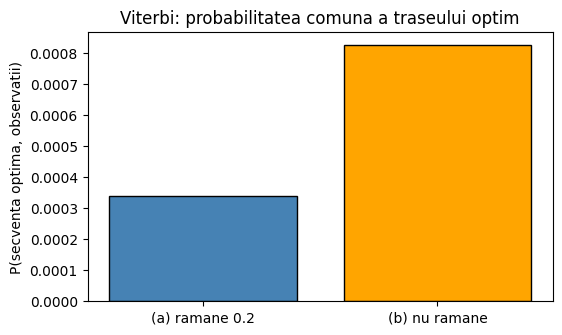

In [20]:
print("Comparatie (a) vs (b)")
print(f"  traseu (a): {[d+1 for d in drum_a]},  P(s*, o) = {p_a:.6e}")
print(f"  traseu (b): {[d+1 for d in drum_b]},  P(s*, o) = {p_b:.6e}")
print(f"  raport (b)/(a) = {p_b / p_a:.4f}   (teoretic: (0.5/0.4)^4 = {(0.5/0.4)**4:.4f})")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["(a) ramane 0.2", "(b) nu ramane"], [p_a, p_b], color=["steelblue", "orange"], edgecolor="black")
ax.set_ylabel("P(secventa optima, observatii)")
ax.set_title("Viterbi: probabilitatea comuna a traseului optim")
plt.show()

## Subiectul 2: Rețele Markov



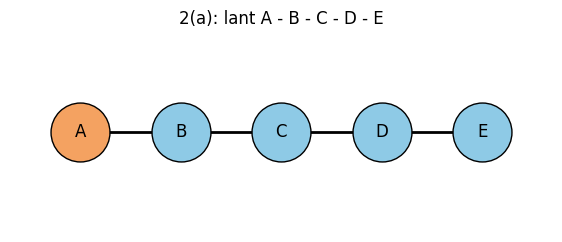

In [21]:
deseneaza_neorientat(
    muchii=[("A", "B"), ("B", "C"), ("C", "D"), ("D", "E")],
    poz={"A": (0, 0), "B": (1, 0), "C": (2, 0), "D": (3, 0), "E": (4, 0)},
    titlu="2(a): lant A - B - C - D - E",
    culori={"A": "#f4a261"},
)

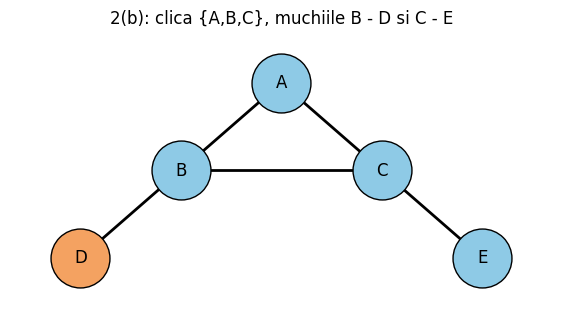

In [22]:
deseneaza_neorientat(
    muchii=[("A", "B"), ("A", "C"), ("B", "C"), ("B", "D"), ("C", "E")],
    poz={"A": (1, 1.2), "B": (0, 0), "C": (2, 0), "D": (-1, -1.2), "E": (3, -1.2)},
    titlu="2(b): clica {A,B,C}, muchiile B - D si C - E",
    culori={"D": "#f4a261"},
    figsize=(7, 3.6),
)

In [23]:
rng = np.random.default_rng(12)
phi1, phi2, phi3, phi4 = (rng.random((2, 2)) + 0.1 for _ in range(4))
psi1 = rng.random((2, 2, 2)) + 0.1
psi2, psi3 = (rng.random((2, 2)) + 0.1 for _ in range(2))

# (a):
P_a = np.einsum("ab,bc,cd,de->abcde", phi1, phi2, phi3, phi4)
P_a /= P_a.sum()
b, c = 1, 0
exact = P_a[:, b, c, :, :].sum(axis=(1, 2)); exact /= exact.sum()
simplificat = phi1[:, b] / phi1[:, b].sum()
print("(a) exact      :", exact.round(6))
print("(a) simplificat:", simplificat.round(6), "  coincid:", np.allclose(exact, simplificat))

# (b):
P_b = np.einsum("abc,bd,ce->abcde", psi1, psi2, psi3)
P_b /= P_b.sum()
a_, b, c, e = 1, 0, 1, 1
exact = P_b[a_, b, c, :, e]; exact /= exact.sum()
simplificat = psi2[b, :] / psi2[b, :].sum()
print("(b) exact      :", exact.round(6))
print("(b) simplificat:", simplificat.round(6), "  coincid:", np.allclose(exact, simplificat))

(a) exact      : [0.78938 0.21062]
(a) simplificat: [0.78938 0.21062]   coincid: True
(b) exact      : [0.136843 0.863157]
(b) simplificat: [0.136843 0.863157]   coincid: True


## Subiectul 3: Inferența Bayesiană



Posterior dupa lotul 1: Beta(7, 23)
Media a priori      : 0.2000
Media a posteriori  : 0.2333   (= 7/30)
MLE y/N             : 0.2500
Interval credibil 94%: [0.1069 0.3899]


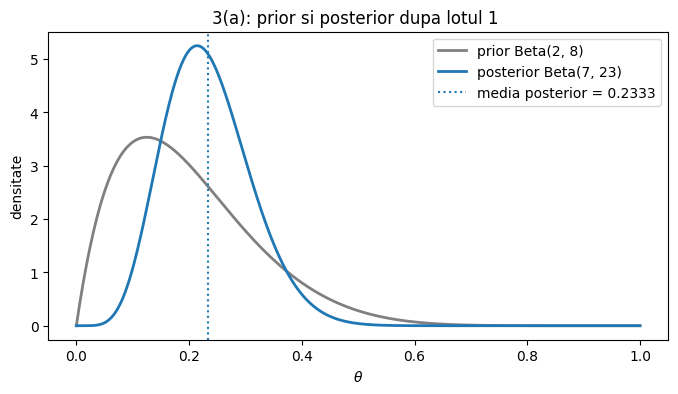

In [24]:
a0, b0 = 2, 8
y1, n1 = 5, 20

a1, b1 = a0 + y1, b0 + (n1 - y1)
print(f"Posterior dupa lotul 1: Beta({a1}, {b1})")
print(f"Media a priori      : {a0 / (a0 + b0):.4f}")
print(f"Media a posteriori  : {a1 / (a1 + b1):.4f}   (= {a1}/{a1 + b1})")
print(f"MLE y/N             : {y1 / n1:.4f}")
print(f"Interval credibil 94%: {beta.ppf([0.03, 0.97], a1, b1).round(4)}")

theta = np.linspace(0, 1, 500)
plt.figure(figsize=(8, 4))
plt.plot(theta, beta.pdf(theta, a0, b0), label=f"prior Beta({a0}, {b0})", color="gray", lw=2)
plt.plot(theta, beta.pdf(theta, a1, b1), label=f"posterior Beta({a1}, {b1})", color="tab:blue", lw=2)
plt.axvline(a1 / (a1 + b1), color="tab:blue", ls=":", label="media posterior = 0.2333")
plt.xlabel(r"$\theta$"); plt.ylabel("densitate"); plt.title("3(a): prior si posterior dupa lotul 1 ")
plt.legend(); plt.show()

In [25]:
y2, n2 = 3, 15

# (b)
a2, b2 = a1 + y2, b1 + (n2 - y2)
print(f"(b) Posterior dupa ambele loturi (secvential): Beta({a2}, {b2}),  media = {a2 / (a2 + b2):.4f}")

a_tot, b_tot = a0 + (y1 + y2), b0 + (n1 + n2 - y1 - y2)
print(f"    Verificare (date combinate 8 din 35):       Beta({a_tot}, {b_tot})  -> coincid: {(a2, b2) == (a_tot, b_tot)}")
print(f"    Interval credibil 94%: {beta.ppf([0.03, 0.97], a2, b2).round(4)}")


from scipy.stats import binom
from scipy.integrate import trapezoid
grid = np.linspace(1e-6, 1 - 1e-6, 20001)
post = beta.pdf(grid, a0, b0) * binom.pmf(y1, n1, grid) * binom.pmf(y2, n2, grid)
post /= trapezoid(post, grid)
print("    Verificare numerica (grid): max |diferenta| fata de Beta(10,35) =",
      np.abs(post - beta.pdf(grid, a2, b2)).max().round(6))

(b) Posterior dupa ambele loturi (secvential): Beta(10, 35),  media = 0.2222
    Verificare (date combinate 8 din 35):       Beta(10, 35)  -> coincid: True
    Interval credibil 94%: [0.1182 0.3472]
    Verificare numerica (grid): max |diferenta| fata de Beta(10,35) = 0.0


### (c) Posterior folosind **numai** al doilea lot, cu distribuția inițială $\text{Beta}(2,8)$

$$\theta\mid y_2\sim\text{Beta}(2+3,\ 8+12)=\text{Beta}(5,20),\qquad \mathbb E[\theta\mid y_2]=\frac{5}{25}=0.2$$

(c) Posterior doar cu lotul 2: Beta(5, 20),  media = 0.2000
    Interval credibil 94%: [0.0748 0.3657]

                distributie  media  dev. standard
            prior Beta(2,8) 0.2000         0.1206
      (a) lot 1: Beta(7,23) 0.2333         0.0760
(b) loturi 1+2: Beta(10,35) 0.2222         0.0613
 (c) doar lot 2: Beta(5,20) 0.2000         0.0784


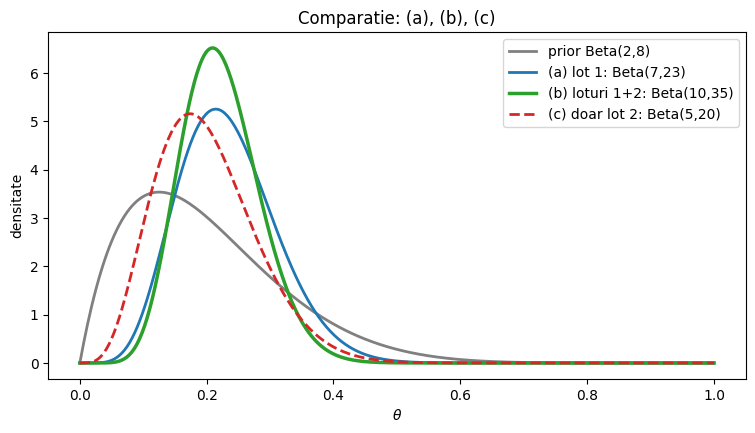

In [26]:
# (c)
a3, b3 = a0 + y2, b0 + (n2 - y2)
print(f"(c) Posterior doar cu lotul 2: Beta({a3}, {b3}),  media = {a3 / (a3 + b3):.4f}")
print(f"    Interval credibil 94%: {beta.ppf([0.03, 0.97], a3, b3).round(4)}")

tabel = pd.DataFrame({
    "distributie": [f"prior Beta({a0},{b0})", f"(a) lot 1: Beta({a1},{b1})",
                    f"(b) loturi 1+2: Beta({a2},{b2})", f"(c) doar lot 2: Beta({a3},{b3})"],
    "media": [a0/(a0+b0), a1/(a1+b1), a2/(a2+b2), a3/(a3+b3)],
    "dev. standard": [beta.std(a, b) for a, b in [(a0, b0), (a1, b1), (a2, b2), (a3, b3)]],
}).round(4)
print()
print(tabel.to_string(index=False))

plt.figure(figsize=(9, 4.5))
plt.plot(theta, beta.pdf(theta, a0, b0), label=f"prior Beta({a0},{b0})", color="gray", lw=2)
plt.plot(theta, beta.pdf(theta, a1, b1), label=f"(a) lot 1: Beta({a1},{b1})", color="tab:blue", lw=2)
plt.plot(theta, beta.pdf(theta, a2, b2), label=f"(b) loturi 1+2: Beta({a2},{b2})", color="tab:green", lw=2.5)
plt.plot(theta, beta.pdf(theta, a3, b3), label=f"(c) doar lot 2: Beta({a3},{b3})", color="tab:red", lw=2, ls="--")
plt.xlabel(r"$\theta$"); plt.ylabel("densitate"); plt.title("Comparatie: (a), (b), (c)")
plt.legend(); plt.show()